<a href="https://colab.research.google.com/github/ColeHernandez/Fatal-Crash-Report/blob/main/Copy_of_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final Project:
## Cole Hernandez || u1463819

### Question:



### Load in data from external source

### Aggregate Data

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
import os

#Creating a base path for the folders.
base_path = "/content/drive/MyDrive/Final_Project_Crash_Data/national_zip_folders"



dfs = []

for year in range(2014, 2021):
    folder = os.path.join(base_path, f"FARS{year}NationalCSV")
    files = os.listdir(folder)
    accident_file = next((f for f in files if f.lower() == 'accident.csv'), None)
    accident_path = os.path.join(folder, accident_file)

    encoding = 'utf-8-sig' if year >= 2021 else 'latin-1'

    df = pd.read_csv(accident_path, encoding=encoding, low_memory=False)
    df['YEAR'] = year
    dfs.append(df)
    print(f"Loaded {year}: {len(df)} rows")

accidents = pd.concat(dfs, ignore_index=True)

print("\nDRUNK_DR null counts by year:")
print(accidents.groupby('YEAR')['DRUNK_DR'].apply(lambda x: x.isna().sum()))







Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 2014: 30056 rows
Loaded 2015: 32538 rows
Loaded 2016: 34748 rows
Loaded 2017: 34560 rows
Loaded 2018: 33919 rows
Loaded 2019: 33487 rows
Loaded 2020: 35935 rows

DRUNK_DR null counts by year:
YEAR
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
Name: DRUNK_DR, dtype: int64


### Clean Data

Now that we have the full national database we can now filter to the two states that we want. Utah and Idaho. There ids are 49 and 16.

In [ ]:
states = [49, 16, 8, 6, 56, 12]
UT_ID = accidents[accidents['STATE'].isin(states)].copy()

#Lets only keep alcohol related crashes.
alcohol = UT_ID[UT_ID['DRUNK_DR'] > 0].copy()

alcohol.head()

,STATE,ST_CASE,VE_TOTAL,VE_FORMS,PVH_INVL,PEDS,PERNOTMVIT,PERMVIT,PERSONS,COUNTY,...,NOT_MINNAME,ARR_HOURNAME,ARR_MINNAME,HOSP_HRNAME,HOSP_MNNAME,CF1NAME,CF2NAME,CF3NAME,COUNTYNAME,CITYNAME
1960,6,60002,1,1,0,0,0,2,2,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1967,6,60009,1,1,0,0,0,1,1,71,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1975,6,60017,1,1,0,0,0,1,1,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1976,6,60018,1,1,0,0,0,1,1,101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1977,6,60019,1,1,0,0,0,5,5,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Now that we have isolated the alcahol related crashes. We can now ignore all rows that have missing values in Drunk_dr and FATALS columns.

In [ ]:
alcohol = alcohol.dropna(subset=['DRUNK_DR', 'FATALS'])
alcohol.head()

,STATE,ST_CASE,VE_TOTAL,VE_FORMS,PVH_INVL,PEDS,PERNOTMVIT,PERMVIT,PERSONS,COUNTY,...,NOT_MINNAME,ARR_HOURNAME,ARR_MINNAME,HOSP_HRNAME,HOSP_MNNAME,CF1NAME,CF2NAME,CF3NAME,COUNTYNAME,CITYNAME
1960,6,60002,1,1,0,0,0,2,2,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1967,6,60009,1,1,0,0,0,1,1,71,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1975,6,60017,1,1,0,0,0,1,1,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1976,6,60018,1,1,0,0,0,1,1,101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1977,6,60019,1,1,0,0,0,5,5,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Look at head, tail, shape, and n's of data.

In [ ]:
alcohol.head()

,STATE,ST_CASE,VE_TOTAL,VE_FORMS,PVH_INVL,PEDS,PERNOTMVIT,PERMVIT,PERSONS,COUNTY,...,NOT_MINNAME,ARR_HOURNAME,ARR_MINNAME,HOSP_HRNAME,HOSP_MNNAME,CF1NAME,CF2NAME,CF3NAME,COUNTYNAME,CITYNAME
1960,6,60002,1,1,0,0,0,2,2,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1967,6,60009,1,1,0,0,0,1,1,71,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1975,6,60017,1,1,0,0,0,1,1,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1976,6,60018,1,1,0,0,0,1,1,101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1977,6,60019,1,1,0,0,0,5,5,37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
alcohol.tail()

,STATE,ST_CASE,VE_TOTAL,VE_FORMS,PVH_INVL,PEDS,PERNOTMVIT,PERMVIT,PERSONS,COUNTY,...,NOT_MINNAME,ARR_HOURNAME,ARR_MINNAME,HOSP_HRNAME,HOSP_MNNAME,CF1NAME,CF2NAME,CF3NAME,COUNTYNAME,CITYNAME
235221,56,560094,1,1,0,0,0,2,2,25,...,14,8:00pm-8:59pm,44,Not Applicable (Not Transported),Not Applicable (Not Transported),NaN,NaN,NaN,NATRONA (25),NOT APPLICABLE
235224,56,560097,1,1,0,0,0,1,1,9,...,3,3:00am-3:59am,21,Unknown,Unknown EMS Hospital Arrival Time,NaN,NaN,NaN,CONVERSE (9),NOT APPLICABLE
235232,56,560105,1,1,0,1,1,1,1,13,...,25,6:00am-6:59am,18,Not Applicable (Not Transported),Not Applicable (Not Transported),NaN,NaN,NaN,FREMONT (13),NOT APPLICABLE
235235,56,560108,2,2,0,0,0,2,2,29,...,16,1:00pm-1:59pm,24,Unknown,Unknown EMS Hospital Arrival Time,NaN,NaN,NaN,PARK (29),NOT APPLICABLE
235236,56,560109,1,1,0,0,0,1,1,9,...,13,7:00pm-7:59pm,24,Not Applicable (Not Transported),Not Applicable (Not Transported),NaN,NaN,NaN,CONVERSE (9),NOT APPLICABLE


In [ ]:
alcohol.describe()

,STATE,ST_CASE,VE_TOTAL,VE_FORMS,PVH_INVL,PEDS,PERNOTMVIT,PERMVIT,PERSONS,COUNTY,...,HOSP_MN,CF1,CF2,CF3,FATALS,DRUNK_DR,DAYNAME,RUR_URB,FUNC_SYS,RD_OWNER
count,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,13562.000000,...,13562.000000,11474.000000,11474.000000,11474.000000,13562.000000,13562.000000,11799.000000,11799.000000,11799.000000,11799.000000
mean,10.627636,107623.153222,1.582141,1.512756,0.069385,0.090547,0.104336,2.243622,2.257410,59.563929,...,91.582068,1.206903,0.143368,0.047760,1.120852,1.033623,15.808119,1.637766,4.091703,32.907958
std,9.625330,95944.397019,0.825225,0.749421,0.386685,0.360133,0.408176,1.644970,1.649118,33.079493,...,14.083131,4.803747,2.520675,2.086716,0.416187,0.183909,8.858887,0.578607,6.330468,44.328797
min,6.000000,60001.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,6.000000,61638.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,35.000000,...,88.000000,0.000000,0.000000,0.000000,1.000000,1.000000,8.000000,1.000000,3.000000,1.000000
50%,8.000000,80027.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,61.000000,...,99.000000,0.000000,0.000000,0.000000,1.000000,1.000000,16.000000,2.000000,3.000000,2.000000
75%,12.000000,121396.750000,2.000000,2.000000,0.000000,0.000000,0.000000,3.000000,3.000000,85.000000,...,99.000000,0.000000,0.000000,0.000000,1.000000,1.000000,24.000000,2.000000,5.000000,98.000000
max,56.000000,560131.000000,14.000000,14.000000,10.000000,11.000000,11.000000,25.000000,25.000000,133.000000,...,99.000000,99.000000,99.000000,99.000000,6.000000,4.000000,31.000000,9.000000,99.000000,99.000000


In [ ]:
alcohol.shape

(13562, 92)

In [ ]:
total_fatals = accidents[accidents['STATE'].isin(states)].groupby(
    ['YEAR', 'STATE'])['FATALS'].sum().reset_index()
total_fatals.columns = ['YEAR', 'STATE', 'TOTAL_FATALS']

alcohol_fatals = alcohol.groupby(
    ['YEAR', 'STATE'])['FATALS'].sum().reset_index()
alcohol_fatals.columns = ['YEAR', 'STATE', 'ALCOHOL_FATALS']

rates = alcohol_fatals.merge(total_fatals, on=['YEAR', 'STATE'])
rates['RATE'] = (rates['ALCOHOL_FATALS'] / rates['TOTAL_FATALS']) * 100

national_totals = accidents.groupby('YEAR')['FATALS'].sum().reset_index()
national_totals.columns = ['YEAR', 'TOTAL_FATALS']

national_alcohol = accidents[accidents['DRUNK_DR'] > 0].groupby('YEAR')['FATALS'].sum().reset_index()
national_alcohol.columns = ['YEAR', 'ALCOHOL_FATALS']

national_rates = national_alcohol.merge(national_totals, on='YEAR')
national_rates['RATE'] = (national_rates['ALCOHOL_FATALS'] / national_rates['TOTAL_FATALS']) * 100

rates_did = rates[rates['STATE'].isin([49,16])].copy()

In [ ]:
print(f"UT: {len(alcohol[alcohol['STATE']== 49])}")
print(f"ID: {len(alcohol[alcohol['STATE']== 16])}")

UT: 352
ID: 442


# Visualizations

### Visualization 1

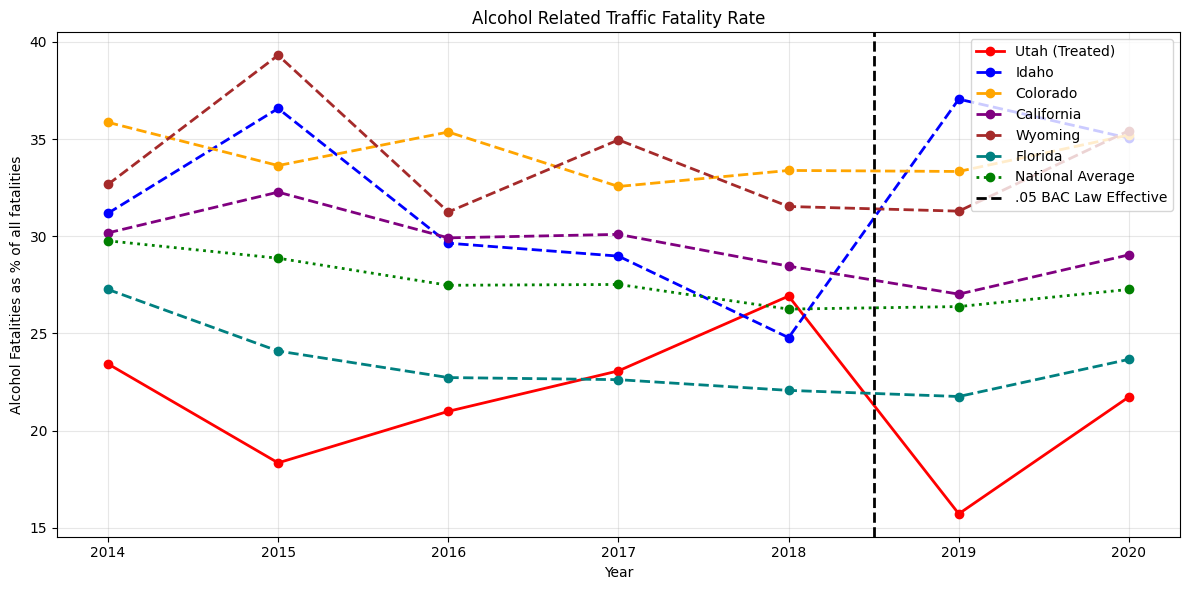

In [ ]:
import matplotlib.pyplot as plt

state_labels = {49: "Utah (Treated)", 16: "Idaho", 8: 'Colorado',
                6:"California", 56:"Wyoming", 12:'Florida'}
state_colors = {49: 'red', 16: 'blue', 8: 'orange', 6: 'purple', 56: 'brown', 12: 'teal'}

plt.figure(figsize=(12, 6))

for state_id, label in state_labels.items():
    s = rates[rates['STATE']==state_id]
    linestyle = '-' if state_id == 49 else '--'
    plt.plot(s['YEAR'], s['RATE'], marker='o', color=state_colors[state_id], linewidth=2, label=label, linestyle=linestyle)

plt.plot(national_rates['YEAR'], national_rates['RATE'], marker='o', color='green', linewidth=2, linestyle='dotted', label='National Average')

plt.axvline(x=2018.5, color='black', linestyle='--', linewidth=2, label='.05 BAC Law Effective')

plt.title('Alcohol Related Traffic Fatality Rate')
plt.xlabel('Year')
plt.ylabel('Alcohol Fatalities as % of all fatalities')
plt.legend(loc='upper right')
plt.xticks(range(2014, 2021))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Visualization 2 - Bar Chart

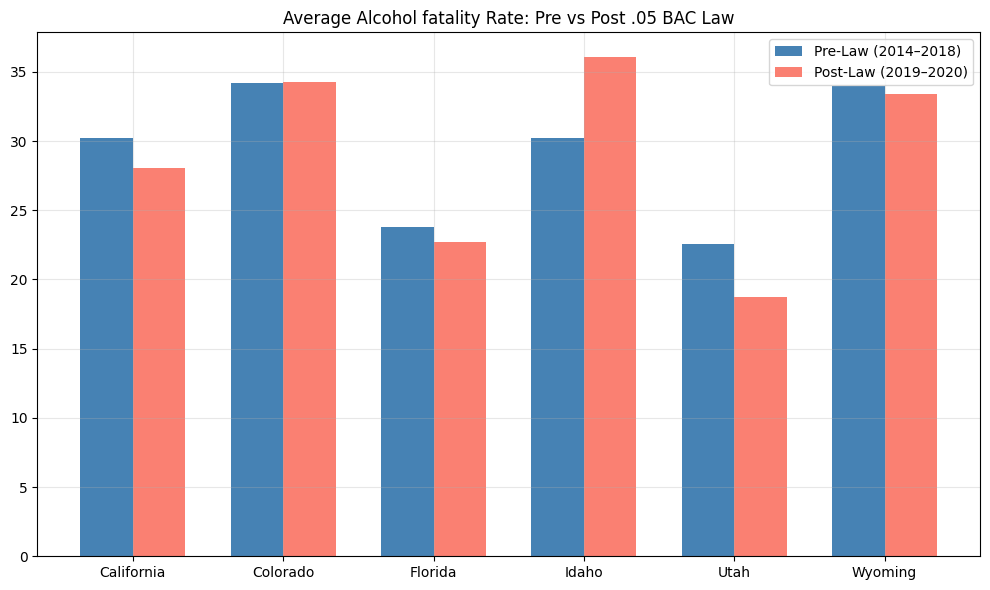

In [ ]:

pre = rates[rates['YEAR'] < 2019].groupby('STATE')['RATE'].mean()
post = rates[rates['YEAR'] >= 2019].groupby('STATE')['RATE'].mean()

state_names = {49: 'Utah', 16: 'Idaho', 8: 'Colorado', 6: 'California', 56: 'Wyoming', 12: 'Florida'}
labels = [state_names[s] for s in pre.index]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, pre.values, width, label='Pre-Law (2014–2018)', color='steelblue')
ax.bar(x + width/2, post.values, width, label='Post-Law (2019–2020)', color='salmon')

ax.set_title('Average Alcohol fatality Rate: Pre vs Post .05 BAC Law')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Visual 3 - Heatmap



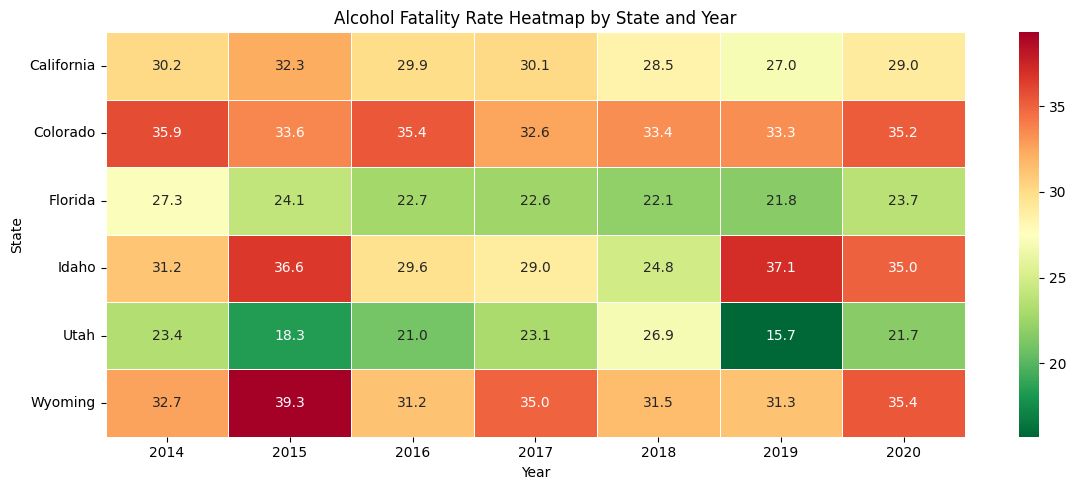

In [ ]:
import seaborn as sns

state_names = {49: 'Utah', 16: 'Idaho', 8: 'Colorado', 6: 'California', 56: 'Wyoming', 12: 'Florida'}
heatmap_data = rates.copy()
heatmap_data['STATE_NAME'] = heatmap_data['STATE'].map(state_names)
heatmap_pivot = heatmap_data.pivot(index='STATE_NAME', columns='YEAR', values='RATE')

plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_pivot, annot=True, fmt='.1f', cmap='RdYlGn_r', linewidths=0.5)
plt.title('Alcohol Fatality Rate Heatmap by State and Year')
plt.ylabel('State')
plt.xlabel('Year')
plt.tight_layout()
plt.show()

# Tests

### Difference in Difference Regression

In [ ]:
import statsmodels.formula.api as smf

did_data = rates_did.copy()
did_data['post_law'] = (did_data['YEAR'] >= 2019).astype(int)
did_data['treated'] = (did_data['STATE'] == 49).astype(int)

model = smf.ols('RATE ~ treated + post_law + treated:post_law', data=did_data).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   RATE   R-squared:                       0.772
Model:                            OLS   Adj. R-squared:                  0.703
Method:                 Least Squares   F-statistic:                     11.27
Date:                Thu, 30 Apr 2026   Prob (F-statistic):            0.00151
Time:                        03:02:30   Log-Likelihood:                -35.628
No. Observations:                  14   AIC:                             79.26
Df Residuals:                      10   BIC:                             81.81
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           30.2334      1.631  

### T-Test

In [ ]:
from scipy import stats

utah_rates = rates[rates['STATE'] == 49]
utah_pre = utah_rates[utah_rates['YEAR'] < 2019]['RATE']
utah_post = utah_rates[utah_rates['YEAR'] >= 2019]['RATE']

t_stat, p_value = stats.ttest_ind(utah_pre, utah_post)
print(f"Utah Pre-Law Mean:  {utah_pre.mean():.2f}%")
print(f"Utah Post-Law Mean: {utah_post.mean():.2f}%")
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_value:.3f}")

Utah Pre-Law Mean:  22.56%
Utah Post-Law Mean: 18.73%
T-statistic: 1.338
P-value: 0.239
